# **Project Name**    -  **Financial Forecasting Frontier: A Distributed Machine Learning Approach**



##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual
##### **Name -** Tushar Gupta


# **Project Summary -**



This project focuses on applying distributed data processing and machine learning techniques to the Bank Marketing dataset. The objective is to analyze customer and campaign-related attributes and build a scalable machine learning workflow for predicting whether a customer will subscribe to a term deposit.

The project combines multiple big-data technologies to demonstrate different stages of a distributed analytics pipeline. Hadoop Distributed File System (HDFS) is used for distributed data storage, while Hadoop MapReduce is used to perform large-scale aggregations and analytical tasks. Apache Hive is used to query the banking dataset using SQL-like operations and derive meaningful business insights from customer demographics, financial attributes, and marketing campaign information.

The next stage of the project uses Apache Spark for exploratory data analysis, data preprocessing, feature engineering, and distributed machine learning. Customer attributes such as age, job, education, balance, housing loan status, personal loan status, contact information, campaign characteristics, and previous campaign outcomes are analyzed to understand their relationship with term-deposit subscription.

Different machine learning classification models will be trained and evaluated using appropriate performance metrics. The project also explores distributed processing concepts and data parallelism to demonstrate how machine learning workflows can be scaled beyond traditional single-machine approaches.

Overall, the project aims to integrate distributed storage, distributed computation, exploratory analysis, and machine learning into an end-to-end pipeline for analyzing bank marketing campaign data and predicting customer subscription behavior.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**




The objective of this project is to develop a distributed machine learning solution for analyzing a bank marketing campaign and predicting whether a customer will subscribe to a term deposit.

The banking dataset contains customer demographic information, financial attributes, loan status, contact details, and information related to current and previous marketing campaigns. Processing and analyzing such data using distributed computing technologies can help identify important patterns associated with customer subscription behavior.

The project uses Hadoop and Hive for distributed storage, processing, and analytical querying, followed by Apache Spark for exploratory data analysis, data preprocessing, feature engineering, and machine learning. The primary prediction target is the `y` variable, which indicates whether a customer subscribed to the term deposit (`yes`) or not (`no`).

The final goal is to build and evaluate classification models capable of identifying customers who are more likely to subscribe, while also demonstrating the use of distributed computing and data parallelism in an end-to-end machine learning workflow.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [64]:
# Import Libraries
# Install PySpark
!pip install pyspark -q

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# PySpark imports
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

### Dataset Loading

In [2]:
# Load Dataset
# Upload Dataset from Local System
from google.colab import files

uploaded = files.upload()

Saving bank.csv to bank.csv


### Dataset First View

In [3]:
# Dataset First Look
# Create Spark Session
spark = SparkSession.builder \
    .appName("Bank Marketing Distributed ML") \
    .getOrCreate()

# Load the uploaded dataset into Spark DataFrame
df = spark.read.csv(
    "bank.csv",
    header=True,
    inferSchema=True
)

# Dataset First View
df.show(5, truncate=False)

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed |married|primary  |no     |1787   |no     |no  |cellular|19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services   |married|secondary|no     |4789   |yes    |yes |cellular|11 |may  |220     |1       |339  |4       |failure |no |
|35 |management |single |tertiary |no     |1350   |yes    |no  |cellular|16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management |married|tertiary |no     |1476   |yes    |yes |unknown |3  |jun  |199     |4       |-1   |0       |unknown |no |
|59 |blue-collar|married|secondary|no     |0      |yes    |no  |unknown |5  |may  |226    

### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count

rows = df.count()
columns = len(df.columns)

print("Number of Rows:", rows)
print("Number of Columns:", columns)

Number of Rows: 4521
Number of Columns: 17


### Dataset Information

In [5]:
# Dataset Info


# Display column names and data types
df.printSchema()

print("\nColumn Names:")
print(df.columns)

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)


Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count


duplicate_count = df.count() - df.dropDuplicates().count()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count

null_counts = df.select([
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df.columns
])

null_counts.show(truncate=False)

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|0  |0  |0      |0        |0      |0      |0      |0   |0      |0  |0    |0       |0       |0    |0       |0       |0  |
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+



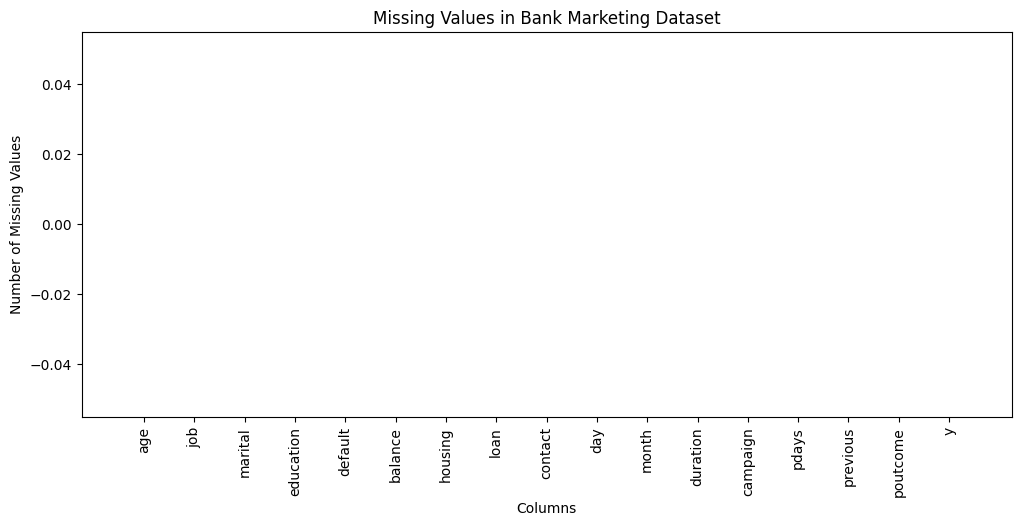

In [8]:
# Visualizing the missing values

null_data = {
    col: df.filter(F.col(col).isNull()).count()
    for col in df.columns
}

null_df = pd.DataFrame(
    list(null_data.items()),
    columns=["Column", "Missing Values"]
)

plt.figure(figsize=(12, 5))
plt.bar(null_df["Column"], null_df["Missing Values"])
plt.xticks(rotation=90)
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values in Bank Marketing Dataset")
plt.show()

### What did you know about your dataset?

Answer Here:- The Bank Marketing dataset contains information related to customers and direct marketing campaigns conducted by a banking institution.

- The dataset contains **4,521 records and 17 features/columns**.
- It includes customer demographic attributes such as **age, job, marital status, and education**.
- Financial information includes **account balance, housing loan, personal loan, and credit default status**.
- Campaign-related attributes include **contact type, contact day and month, call duration, number of campaign contacts, previous contacts, and previous campaign outcome**.
- The target variable is **`y`**, which indicates whether the customer subscribed to a term deposit (`yes` or `no`).
- The dataset contains both **numerical and categorical features**, making preprocessing and feature transformation necessary before machine learning.
- Duplicate and missing-value checks were performed during the initial data inspection.
- Overall, the dataset is suitable for a **binary classification problem**, where the objective is to predict customer term-deposit subscription.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns

print("Dataset Columns:")
for column in df.columns:
    print(column)

Dataset Columns:
age
job
marital
education
default
balance
housing
loan
contact
day
month
duration
campaign
pdays
previous
poutcome
y


In [10]:
# Dataset Describe

df.describe().show(truncate=False)

+-------+------------------+-------+--------+---------+-------+------------------+-------+----+--------+------------------+-----+------------------+------------------+------------------+------------------+--------+----+
|summary|age               |job    |marital |education|default|balance           |housing|loan|contact |day               |month|duration          |campaign          |pdays             |previous          |poutcome|y   |
+-------+------------------+-------+--------+---------+-------+------------------+-------+----+--------+------------------+-----+------------------+------------------+------------------+------------------+--------+----+
|count  |4521              |4521   |4521    |4521     |4521   |4521              |4521   |4521|4521    |4521              |4521 |4521              |4521              |4521              |4521              |4521    |4521|
|mean   |41.17009511170095 |NULL   |NULL    |NULL     |NULL   |1422.6578190665782|NULL   |NULL|NULL    |15.9152842291528

### Variables Description

Answer Here:- The dataset contains 17 variables describing customer characteristics, financial status, and marketing campaign information:

- **age:** Age of the customer.
- **job:** Type of occupation of the customer.
- **marital:** Marital status of the customer.
- **education:** Education level of the customer.
- **default:** Indicates whether the customer has credit in default.
- **balance:** Average yearly account balance of the customer.
- **housing:** Indicates whether the customer has a housing loan.
- **loan:** Indicates whether the customer has a personal loan.
- **contact:** Type of communication used to contact the customer.
- **day:** Day of the month on which the customer was last contacted.
- **month:** Month in which the customer was last contacted.
- **duration:** Duration of the last contact with the customer, measured in seconds.
- **campaign:** Number of contacts performed during the current campaign for the customer.
- **pdays:** Number of days since the customer was previously contacted in an earlier campaign. A value of -1 indicates that the customer was not previously contacted.
- **previous:** Number of contacts performed before the current campaign for the customer.
- **poutcome:** Outcome of the previous marketing campaign.
- **y:** Target variable indicating whether the customer subscribed to a term deposit (`yes` or `no`).

The target variable `y` makes this a binary classification problem.

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.

for column in df.columns:
    unique_count = df.select(column).distinct().count()
    print(f"{column}: {unique_count} unique values")

age: 67 unique values
job: 12 unique values
marital: 3 unique values
education: 4 unique values
default: 2 unique values
balance: 2353 unique values
housing: 2 unique values
loan: 2 unique values
contact: 3 unique values
day: 31 unique values
month: 12 unique values
duration: 875 unique values
campaign: 32 unique values
pdays: 292 unique values
previous: 24 unique values
poutcome: 4 unique values
y: 2 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.

# 1. Remove duplicate rows (if any)
df_clean = df.dropDuplicates()

# 2. Remove rows containing null values (if any)
df_clean = df_clean.dropna()

# 3. Trim extra spaces from all string columns
string_columns = [
    field.name for field in df_clean.schema.fields
    if isinstance(field.dataType, StringType)
]

for column in string_columns:
    df_clean = df_clean.withColumn(column, F.trim(F.col(column)))

# 4. Convert categorical string values to lowercase for consistency
for column in string_columns:
    df_clean = df_clean.withColumn(column, F.lower(F.col(column)))

# 5. Verify the cleaned dataset
print("Rows after cleaning:", df_clean.count())
print("Columns after cleaning:", len(df_clean.columns))

df_clean.show(5, truncate=False)

Rows after cleaning: 4521
Columns after cleaning: 17
+---+------------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job         |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+------------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|35 |entrepreneur|single |tertiary |no     |145    |yes    |no  |cellular|18 |jul  |799     |2       |-1   |0       |unknown |yes|
|33 |blue-collar |married|primary  |no     |-195   |no     |no  |unknown |20 |sep  |9       |1       |-1   |0       |unknown |no |
|59 |unemployed  |married|primary  |no     |0      |no     |no  |cellular|30 |jan  |3025    |2       |-1   |0       |unknown |no |
|28 |management  |single |tertiary |no     |0      |yes    |no  |cellular|16 |jul  |767     |5       |-1   |0       |unknown |yes|
|26 |admin.      |single |seco

### What all manipulations have you done and insights you found?

Answer Here:

The following data wrangling steps were performed to make the dataset ready for further analysis:

- Duplicate records were checked and removed using Spark's `dropDuplicates()` method.
- Missing or null values were checked and rows containing null values were removed, if present.
- All categorical/string columns were identified automatically from the Spark DataFrame schema.
- Extra leading and trailing spaces were removed from categorical values using the `trim()` function.
- Categorical values were converted to lowercase to maintain consistency and avoid treating differently formatted values as separate categories.
- The cleaned dataset was stored in a new Spark DataFrame named `df_clean`, while the original dataset was retained unchanged.

After data wrangling, the dataset contains structured numerical and categorical variables related to customer demographics, financial information, and marketing campaign activities. The target variable `y` represents whether a customer subscribed to the term deposit. The cleaned dataset is now suitable for exploratory data analysis and visualization.

Detailed relationships and business insights will be investigated in the subsequent EDA and visualization sections rather than making conclusions during the data-cleaning stage.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

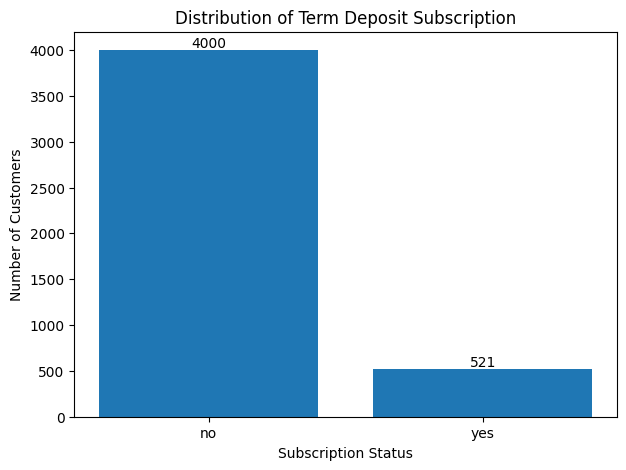

In [13]:
# Chart - 1 visualization code

# Chart - 1: Distribution of Term Deposit Subscription

subscription_counts = (
    df_clean.groupBy("y")
    .count()
    .orderBy("y")
    .toPandas()
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    subscription_counts["y"],
    subscription_counts["count"]
)

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

# Display values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected because the target variable `y` is categorical and contains two classes: `yes` and `no`. The chart provides a clear comparison of the number of customers who subscribed to the term deposit and those who did not. It also helps identify whether the target variable is balanced or imbalanced before building classification models.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows a significant class imbalance in the target variable. Out of 4,521 customers, 4,000 customers did not subscribe to the term deposit, while only 521 customers subscribed.

This means that approximately 88.5% of the customers belong to the `no` category, whereas only about 11.5% belong to the `yes` category. Therefore, successful subscriptions represent a relatively small proportion of the overall marketing campaign.

This class imbalance will also be important during machine learning because model performance should not be evaluated using accuracy alone.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can create a positive business impact because it shows that only a small proportion of contacted customers successfully subscribe to the term deposit. The bank can use further analysis and predictive modelling to identify customers with a higher probability of subscription and target them more effectively.

The low subscription rate may have a negative business impact if the bank continues contacting a large number of customers who are unlikely to subscribe. This can increase marketing costs, consume employee time, and reduce campaign efficiency.

By identifying the characteristics of successful subscribers, the bank can improve customer targeting, reduce unnecessary contacts, and potentially increase the conversion rate of future marketing campaigns.

#### Chart - 2

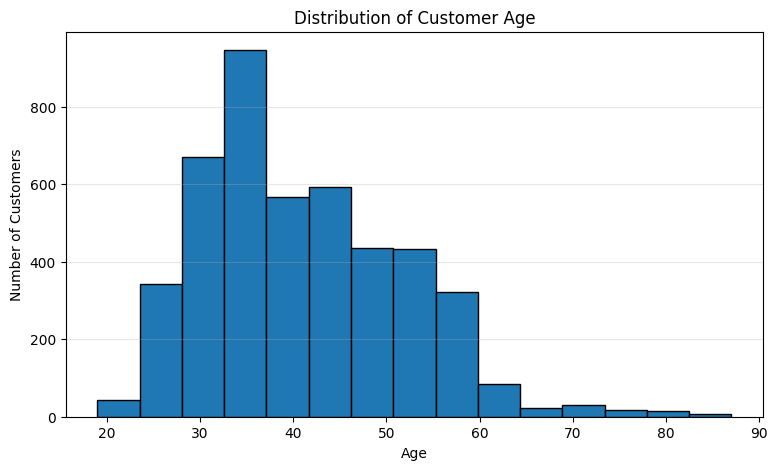

In [14]:
# Chart - 2 visualization code

# Chart - 2: Distribution of Customer Age

age_data = df_clean.select("age").toPandas()

plt.figure(figsize=(9, 5))

plt.hist(
    age_data["age"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)

plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A histogram was selected because `age` is a numerical variable. It helps visualize the distribution of customers across different age ranges and makes it easier to identify where most customers are concentrated, as well as whether there are relatively younger or older customers in the dataset.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The age distribution shows that most customers are concentrated between approximately 30 and 60 years of age, with the highest concentration appearing among customers in their 30s.

The number of customers gradually decreases at higher ages, and relatively few customers are above 60 years old. The distribution therefore indicates that the bank's marketing dataset primarily represents working-age customers, while older customers form a much smaller segment.

This suggests that age may be an important demographic variable to investigate further in relation to term-deposit subscription.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, understanding the age distribution can help the bank design more targeted marketing strategies for different customer age groups. Since a large proportion of customers are within the 30–60 age range, this segment represents an important part of the bank's existing marketing audience.

However, customer frequency alone does not indicate which age group has the highest probability of subscribing. Targeting customers only because they belong to the most common age group could lead to inefficient marketing expenditure.

Therefore, age should be analyzed together with subscription status and other customer characteristics before making targeting decisions. This can help the bank improve campaign efficiency and reduce unnecessary marketing efforts.

#### Chart - 3

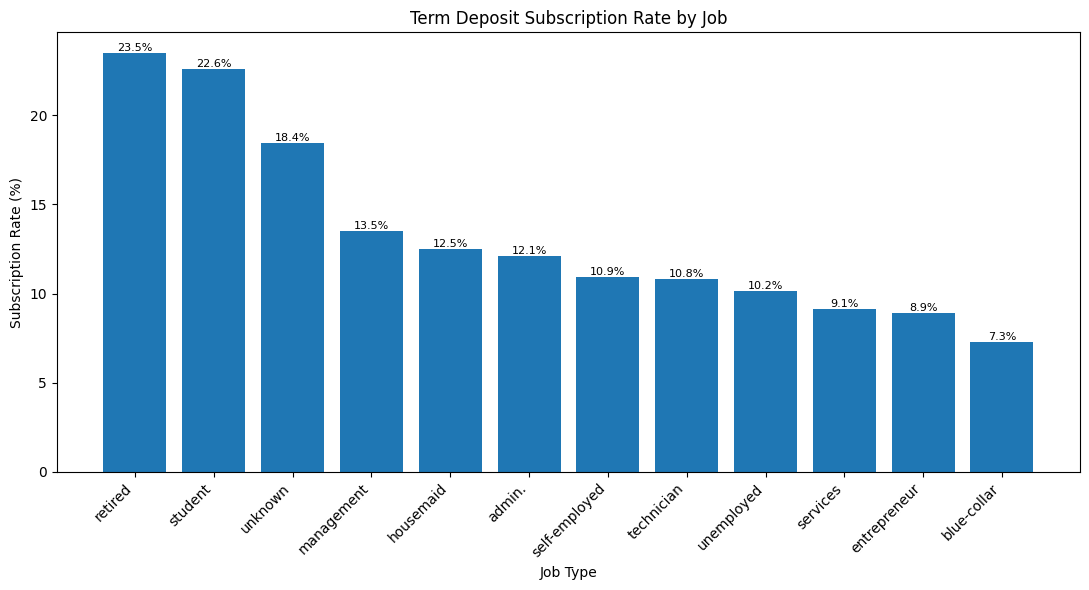

In [15]:
# Chart - 3 visualization code

# Chart - 3: Term Deposit Subscription Rate by Job

job_subscription = (
    df_clean.groupBy("job")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(F.when(F.col("y") == "yes", 1).otherwise(0)).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round((F.col("subscribed") / F.col("total_customers")) * 100, 2)
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    job_subscription["job"],
    job_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare the term-deposit subscription rates across different job categories. Since `job` is a categorical variable and the objective is to compare subscription performance among multiple customer groups, a bar chart provides a clear and easy-to-interpret comparison. Using subscription rate instead of only customer counts also allows job categories of different sizes to be compared more fairly.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows noticeable differences in term-deposit subscription rates across job categories. Retired customers have the highest subscription rate at approximately 23.5%, followed closely by students at approximately 22.6%. The `unknown` job category also shows a relatively high subscription rate of about 18.4%.

Management customers have a subscription rate of approximately 13.5%, while several other occupational groups remain around 9–12%. Blue-collar customers show the lowest subscription rate at approximately 7.3%.

These results indicate that occupation is associated with differences in customer subscription behaviour and may therefore provide useful information for customer segmentation and predictive modelling.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, these insights can help create a positive business impact by allowing the bank to develop more targeted marketing strategies for different occupational segments. Groups such as retired customers and students show relatively high subscription rates and may be useful segments for further investigation and targeted campaigns.

On the other hand, repeatedly allocating the same marketing resources to segments with relatively low conversion rates, such as blue-collar customers, may reduce campaign efficiency and increase marketing costs.

However, job category should not be used as the only criterion for targeting customers. The bank should combine occupation with other variables such as age, balance, previous campaign outcome, loan status, and contact characteristics before making marketing decisions.

#### Chart - 4

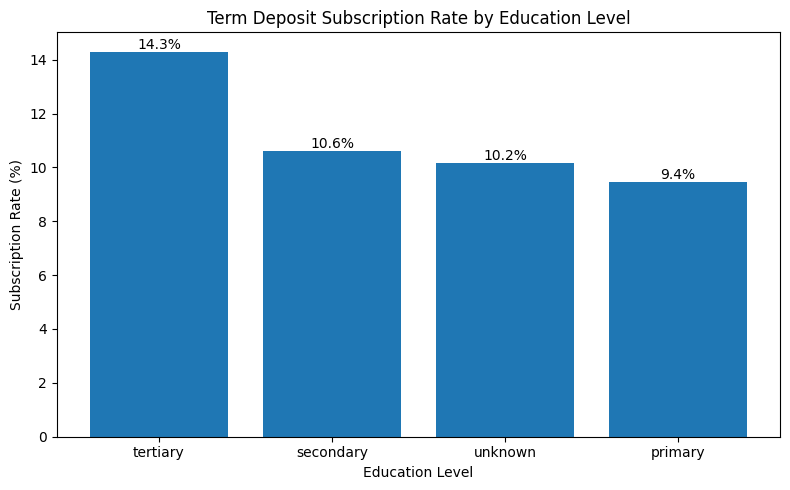

In [16]:
# Chart - 4 visualization code
# Chart - 4: Term Deposit Subscription Rate by Education Level

education_subscription = (
    df_clean.groupBy("education")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_customers")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    education_subscription["education"],
    education_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare term-deposit subscription rates across different education levels. Since education is a categorical variable, a bar chart provides a simple and effective way to compare the subscription behaviour of different educational groups. Subscription rate was used instead of only customer counts to provide a fair comparison between groups of different sizes.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows that customers with tertiary education have the highest term-deposit subscription rate at approximately 14.3%.

Customers with secondary education have a subscription rate of approximately 10.6%, followed by customers with unknown education at 10.2%. Customers with primary education have the lowest subscription rate at approximately 9.4%.

The results suggest that subscription behaviour differs across education levels, with tertiary-educated customers showing a relatively higher tendency to subscribe to the term deposit.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, these insights can support a positive business impact by helping the bank understand how subscription rates vary across educational segments. Customers with tertiary education show the highest subscription rate, making this group potentially useful for more focused marketing analysis.

The relatively lower subscription rate among primary-educated customers may indicate that applying the same marketing strategy across all education groups could result in inefficient resource allocation and lower campaign effectiveness.

However, education level alone should not determine customer targeting. It should be combined with other variables such as job, age, balance, loan status, and previous campaign performance to develop more accurate customer targeting strategies.

#### Chart - 5

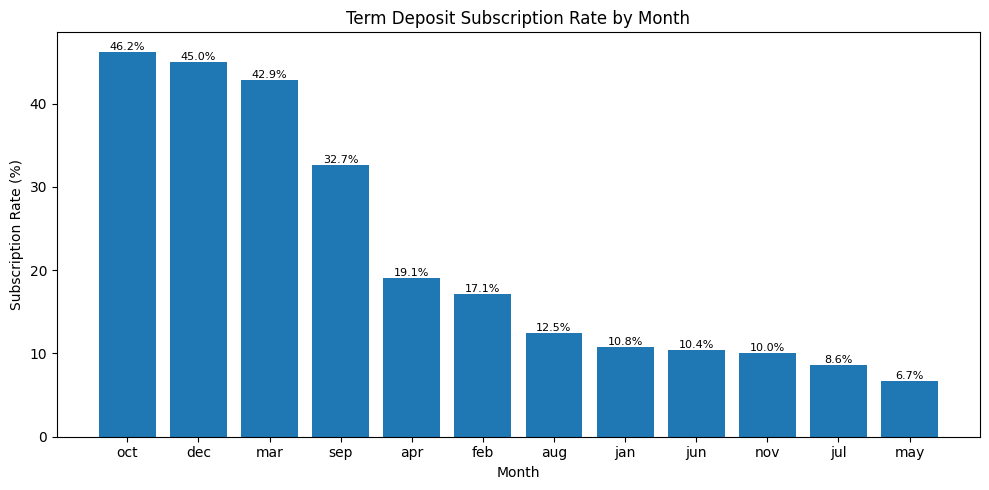

In [17]:
# Chart - 5 visualization code
# Chart - 5: Term Deposit Subscription Rate by Month

month_subscription = (
    df_clean.groupBy("month")
    .agg(
        F.count("*").alias("total_contacts"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_contacts")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    month_subscription["month"],
    month_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare term-deposit subscription rates across different months. Since `month` is a categorical time-related variable, the chart provides a clear comparison of campaign performance across different periods of the year. Subscription rate was used instead of only the number of subscriptions because the number of customers contacted varies across months.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart reveals substantial variation in term-deposit subscription rates across different months.

October has the highest subscription rate at approximately 46.2%, followed by December at 45.0% and March at 42.9%. September also performs relatively well with a subscription rate of approximately 32.7%.

In contrast, May has the lowest subscription rate at approximately 6.7%, followed by July at 8.6%. This indicates that the timing of customer contact is associated with considerable differences in campaign conversion rates.

However, these percentages should be interpreted together with the number of customers contacted in each month, because months with fewer contacts can produce high percentage rates from relatively small samples.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, these insights can help the bank improve the timing and allocation of its marketing campaigns. Months such as October, December, and March show substantially higher subscription rates and can be investigated further to understand the conditions associated with successful conversions.

The very low subscription rate observed in May may indicate inefficient campaign performance during that period. Allocating large marketing resources to periods with low conversion rates could increase campaign costs without generating proportional returns.

However, the bank should not shift its marketing budget based only on monthly subscription rates. The number and type of customers contacted in each month should also be considered before making business decisions. Combining month with customer characteristics and previous campaign information can lead to more reliable targeting strategies.

#### Chart - 6

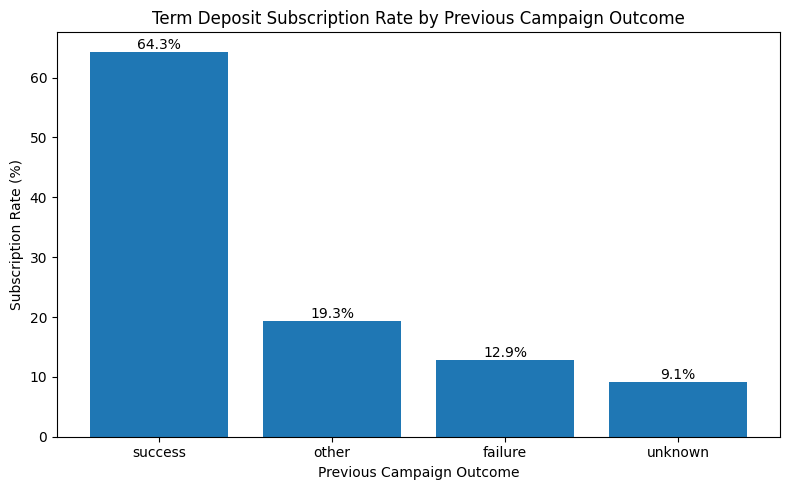

In [18]:
# Chart - 6 visualization code
# Chart - 6: Subscription Rate by Previous Campaign Outcome

poutcome_subscription = (
    df_clean.groupBy("poutcome")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_customers")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    poutcome_subscription["poutcome"],
    poutcome_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare the term-deposit subscription rates across different outcomes of the previous marketing campaign. Since `poutcome` is a categorical variable, a bar chart clearly shows how current subscription behaviour differs depending on the customer's previous campaign outcome.

This comparison is particularly useful for understanding whether historical campaign responses can provide useful information for future marketing decisions.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows a strong difference in current subscription rates based on the outcome of the previous marketing campaign.

Customers whose previous campaign outcome was `success` have the highest current subscription rate at approximately 64.3%. This is substantially higher than the `other` category at 19.3%, `failure` at 12.9%, and `unknown` at 9.1%.

This indicates that customers who responded successfully to a previous campaign are much more likely to subscribe again in the current campaign. Therefore, previous campaign outcome appears to be an important variable for understanding customer subscription behaviour.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can create a strong positive business impact. Customers with a successful previous campaign outcome show a much higher subscription rate, suggesting that historical campaign response can be useful for identifying high-potential customers.

The bank could prioritize previously successful customers or similar customer profiles when designing future campaigns, potentially improving conversion rates and reducing unnecessary marketing expenditure.

On the negative side, repeatedly allocating large marketing resources to customers with unknown or unsuccessful previous outcomes without additional targeting may result in lower conversion efficiency and higher campaign costs.

However, previous campaign outcome should be combined with other customer and campaign characteristics rather than being used as the only factor for targeting decisions.

#### Chart - 7

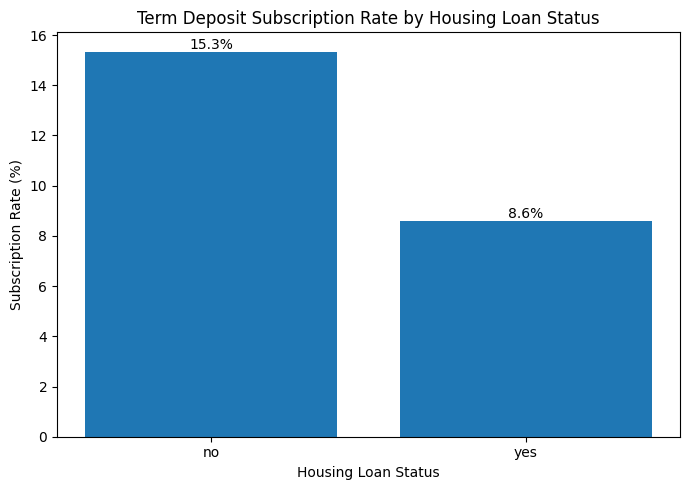

In [19]:
# Chart - 7 visualization code
# Chart - 7: Term Deposit Subscription Rate by Housing Loan Status

housing_subscription = (
    df_clean.groupBy("housing")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_customers")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    housing_subscription["housing"],
    housing_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Housing Loan Status")
plt.xlabel("Housing Loan Status")
plt.ylabel("Subscription Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare the term-deposit subscription rates between customers with and without a housing loan. Since `housing` is a categorical variable with two categories, the bar chart provides a simple and clear comparison of subscription behaviour between these customer groups.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows that customers without a housing loan have a considerably higher term-deposit subscription rate of approximately 15.3%, compared with approximately 8.6% for customers who have a housing loan.

This indicates an association between housing loan status and term-deposit subscription behaviour. Customers without a housing loan appear more likely to subscribe to the term deposit in this dataset.

However, this relationship does not by itself establish that having a housing loan causes the lower subscription rate, as other customer characteristics may also influence the outcome.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can help the bank improve customer segmentation and campaign targeting. Customers without housing loans show a higher subscription rate and may represent a potentially responsive segment for term-deposit campaigns.

The lower subscription rate among customers with housing loans may indicate that applying the same marketing strategy to both groups could reduce campaign efficiency and increase unnecessary marketing costs.

However, customers with housing loans should not simply be excluded from campaigns. Housing loan status should be combined with other variables such as balance, age, job, previous campaign outcome, and contact history to identify customers with a higher probability of subscription.

#### Chart - 8

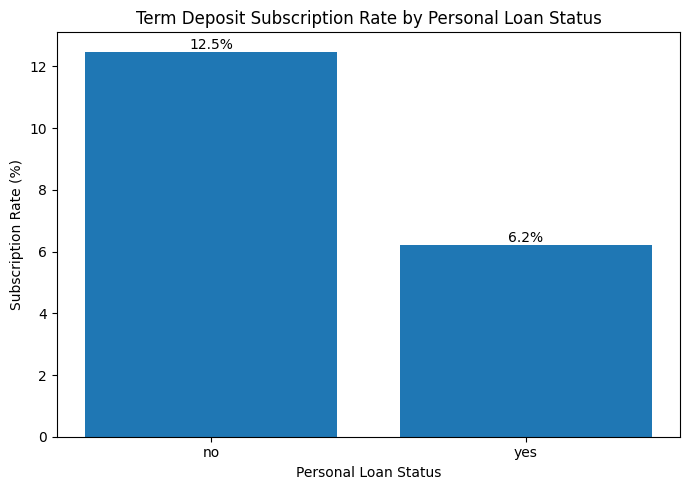

In [20]:
# Chart - 8 visualization code
# Chart - 8: Term Deposit Subscription Rate by Personal Loan Status

loan_subscription = (
    df_clean.groupBy("loan")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_customers")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    loan_subscription["loan"],
    loan_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Personal Loan Status")
plt.xlabel("Personal Loan Status")
plt.ylabel("Subscription Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare the term-deposit subscription rates between customers with and without a personal loan. Since `loan` is a categorical variable with two categories, the bar chart provides a clear and direct comparison of subscription behaviour between these customer groups.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows that customers without a personal loan have a term-deposit subscription rate of approximately 12.5%, while customers with a personal loan have a considerably lower subscription rate of approximately 6.2%.

Therefore, customers without a personal loan show roughly twice the subscription rate of customers who already have a personal loan. This indicates an association between personal loan status and term-deposit subscription behaviour in the dataset.

However, this relationship should not be interpreted as causation because other financial and demographic factors may also influence the customer's decision to subscribe.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can help the bank improve customer segmentation and marketing efficiency. Customers without personal loans show a considerably higher subscription rate and may represent a more responsive segment for term-deposit campaigns.

The relatively low subscription rate among customers with personal loans suggests that repeatedly targeting this group with the same marketing strategy could result in lower conversion efficiency and unnecessary campaign costs.

However, customers with personal loans should not be excluded automatically. Loan status should be combined with other factors such as balance, age, job, housing loan status, and previous campaign outcome before making targeting decisions.

#### Chart - 9

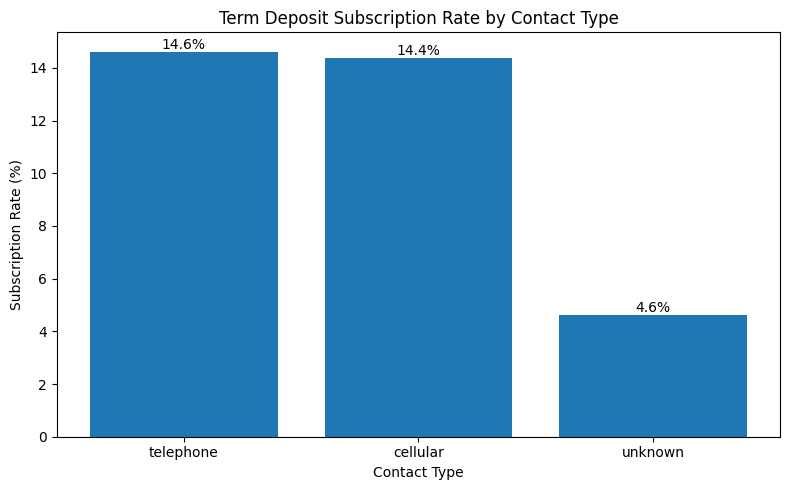

In [21]:
# Chart - 9 visualization code
# Chart - 9: Term Deposit Subscription Rate by Contact Type

contact_subscription = (
    df_clean.groupBy("contact")
    .agg(
        F.count("*").alias("total_customers"),
        F.sum(
            F.when(F.col("y") == "yes", 1).otherwise(0)
        ).alias("subscribed")
    )
    .withColumn(
        "subscription_rate",
        F.round(
            (F.col("subscribed") / F.col("total_customers")) * 100,
            2
        )
    )
    .orderBy(F.desc("subscription_rate"))
    .toPandas()
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    contact_subscription["contact"],
    contact_subscription["subscription_rate"]
)

plt.title("Term Deposit Subscription Rate by Contact Type")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A bar chart was selected to compare term-deposit subscription rates across different contact types. Since `contact` is a categorical variable, a bar chart provides a clear comparison of customer subscription behaviour across telephone, cellular, and unknown contact categories.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows that customers contacted through telephone and cellular channels have very similar term-deposit subscription rates, at approximately 14.6% and 14.4% respectively.

In contrast, the `unknown` contact category has a considerably lower subscription rate of approximately 4.6%.

This suggests that records with a known contact method are associated with higher subscription rates than records where the contact type is unknown. However, there is very little difference between telephone and cellular subscription rates.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, these insights can help the bank evaluate its customer communication strategy. Both telephone and cellular contact categories show considerably higher subscription rates than the unknown contact category.

The low subscription rate associated with unknown contact information may indicate lower campaign effectiveness for such records. Improving customer contact information and maintaining accurate communication records could therefore support more effective campaign targeting.

However, the small difference between telephone and cellular rates does not provide strong evidence that one of these channels should be preferred solely on the basis of this chart. Other factors such as contact cost, customer characteristics, timing, and campaign history should also be considered.

#### Chart - 10

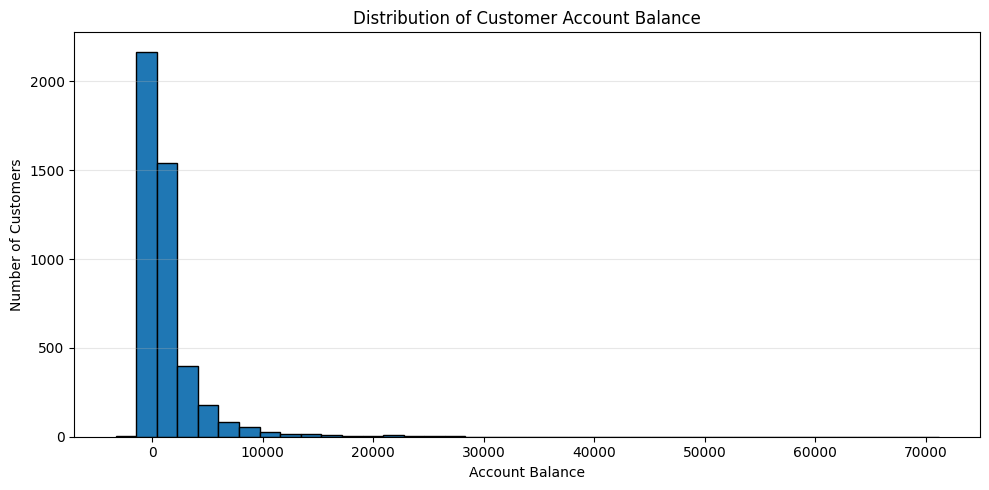

In [22]:
# Chart - 10 visualization code
# Chart - 10: Distribution of Customer Account Balance

balance_data = df_clean.select("balance").toPandas()

plt.figure(figsize=(10, 5))

plt.hist(
    balance_data["balance"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Customer Account Balance")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A histogram was selected because `balance` is a numerical variable and the objective is to understand how customer account balances are distributed.

The histogram helps identify the concentration of balances, the shape and skewness of the distribution, and the presence of unusually high or low balance values.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The account balance distribution is highly right-skewed. Most customers have balances concentrated in the lower range, while a relatively small number of customers have very high account balances.

The distribution also contains some negative balance values, indicating that certain customers have balances below zero. A long tail extends toward higher balance values, with a few exceptionally high balances.

These extreme values indicate the presence of potential outliers and explain why the balance distribution is not symmetric.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, understanding the balance distribution can help the bank segment customers according to their financial profiles and design more appropriate marketing strategies.

Customers with different balance levels may have different financial needs and investment capacity. Therefore, balance can potentially provide useful information when identifying customers for term-deposit campaigns.

The presence of extreme balance values can negatively affect statistical analysis and some machine learning models if they are not handled appropriately. However, these values should not be removed automatically because they may represent genuine high-value customers.

Therefore, outliers should be investigated carefully during preprocessing, and balance should be analyzed together with subscription behaviour and other customer characteristics before making business decisions.

#### Chart - 11

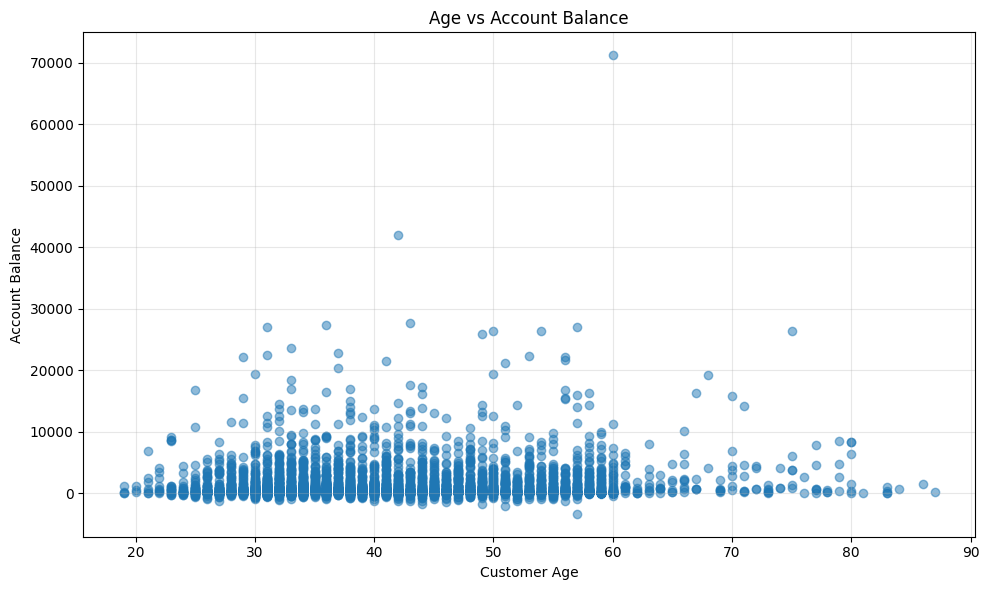

In [23]:
# Chart - 11 visualization code
# Chart - 11: Age vs Account Balance

age_balance_data = df_clean.select("age", "balance").toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    age_balance_data["age"],
    age_balance_data["balance"],
    alpha=0.5
)

plt.title("Age vs Account Balance")
plt.xlabel("Customer Age")
plt.ylabel("Account Balance")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A scatter plot was selected because both `age` and `balance` are numerical variables. It helps visualize the relationship between customer age and account balance, identify any possible trend or correlation, and detect unusual high-balance observations.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The scatter plot shows no strong linear relationship between customer age and account balance. Customers across different age groups generally have balances concentrated in the lower range.

A few customers have exceptionally high balances, including one observation above 70,000, indicating the presence of potential outliers.

Overall, age alone does not appear to be a strong indicator of account balance, as customers of similar ages can have considerably different balance values.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can help the bank understand that customer age should not be used alone to estimate financial capacity or determine marketing targets.

For better customer segmentation, age should be combined with variables such as account balance, job, loan status, education, and previous campaign behaviour.

The presence of extreme balance values may influence statistical analysis and some machine learning models. Therefore, these observations should be investigated during preprocessing rather than automatically removed, as they may represent genuine high-value customers.

#### Chart - 12

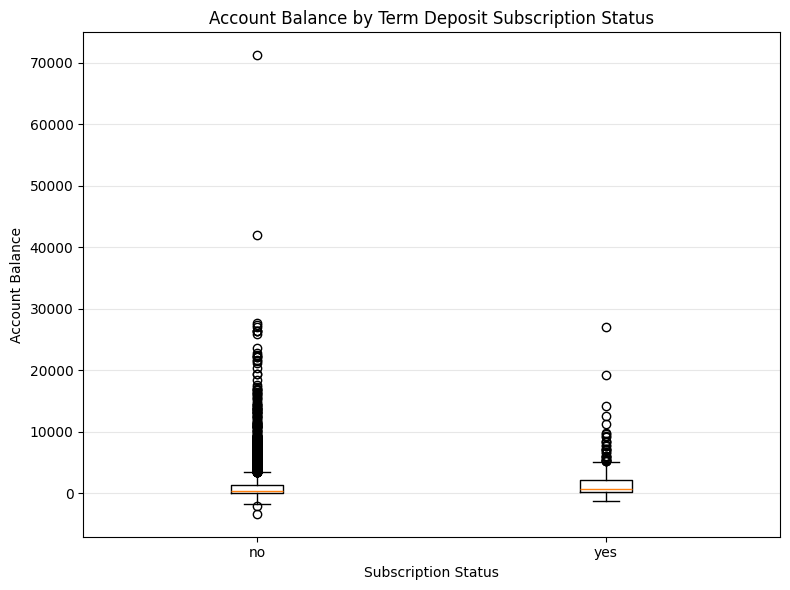

In [24]:
# Chart - 12 visualization code
# Chart - 12: Account Balance by Subscription Status

balance_subscription = (
    df_clean
    .select("y", "balance")
    .toPandas()
)

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        balance_subscription[
            balance_subscription["y"] == "no"
        ]["balance"],

        balance_subscription[
            balance_subscription["y"] == "yes"
        ]["balance"]
    ],
    tick_labels=["no", "yes"]
)

plt.title("Account Balance by Term Deposit Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Account Balance")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A box plot was selected to compare the distribution of account balances between customers who subscribed to the term deposit and those who did not.

The box plot is useful for comparing the median, spread, and potential outliers of a numerical variable across different categorical groups.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The box plot shows differences in the distribution of account balances between subscribed and non-subscribed customers.

Customers who subscribed appear to have a somewhat higher central balance level than customers who did not subscribe. However, both groups show substantial variability and contain several high-balance outliers.

The non-subscribed group contains some particularly extreme balance values, including an observation above 70,000. Therefore, a high account balance alone does not guarantee that a customer will subscribe to the term deposit.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, the insight suggests that account balance may provide useful information when identifying potential term-deposit customers, but it should not be used as the only targeting criterion.

The presence of high-balance customers who did not subscribe shows that targeting customers solely because they have large balances could lead to inefficient marketing expenditure.

The bank should therefore combine balance with other variables such as previous campaign outcome, loan status, job, age, and contact history to develop more effective customer targeting strategies.

#### Chart - 13

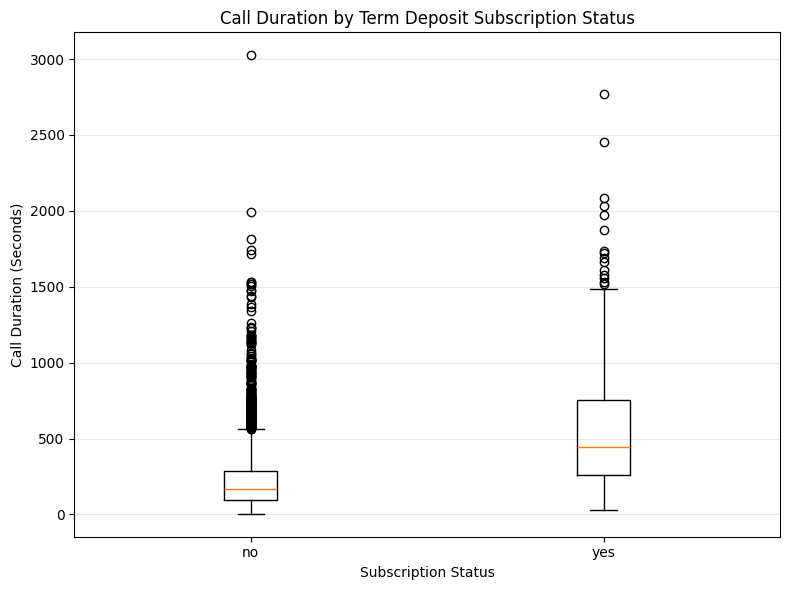

In [25]:
# Chart - 13 visualization code
# Chart - 13: Call Duration by Subscription Status

duration_subscription = (
    df_clean
    .select("y", "duration")
    .toPandas()
)

plt.figure(figsize=(8, 6))

plt.boxplot(
    [
        duration_subscription[
            duration_subscription["y"] == "no"
        ]["duration"],

        duration_subscription[
            duration_subscription["y"] == "yes"
        ]["duration"]
    ],
    tick_labels=["no", "yes"]
)

plt.title("Call Duration by Term Deposit Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Call Duration (Seconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A box plot was selected to compare the distribution of call duration between customers who subscribed to the term deposit and those who did not.

Since `duration` is a numerical variable and `y` is a categorical target variable, the box plot helps compare the median, spread, and outliers of call duration across the two subscription groups.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The chart shows a clear difference in call duration between subscribed and non-subscribed customers.

Customers who subscribed to the term deposit generally had longer calls, with a noticeably higher median call duration than customers who did not subscribe. The subscribed group also shows a wider distribution of call durations.

Both groups contain long-duration outliers, but the overall pattern indicates a strong association between longer conversations and successful term-deposit subscriptions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here:- Yes, this insight can help the bank understand customer engagement during marketing calls. Longer conversations are associated with higher subscription success, which may indicate that interested customers tend to remain engaged with the representative for a longer period.

This could help the bank improve call quality, customer engagement strategies, and sales-agent training.

However, simply increasing call duration should not be treated as a strategy for increasing subscriptions because longer duration may be a result of customer interest rather than its cause. Unnecessarily extending calls could increase operational costs without improving conversions.

Additionally, call duration should be used carefully in predictive modelling because the complete duration is only known after the call has taken place, which can cause data leakage if the objective is to predict subscription before making the call.

#### Chart - 14 - Correlation Heatmap

Numerical Columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


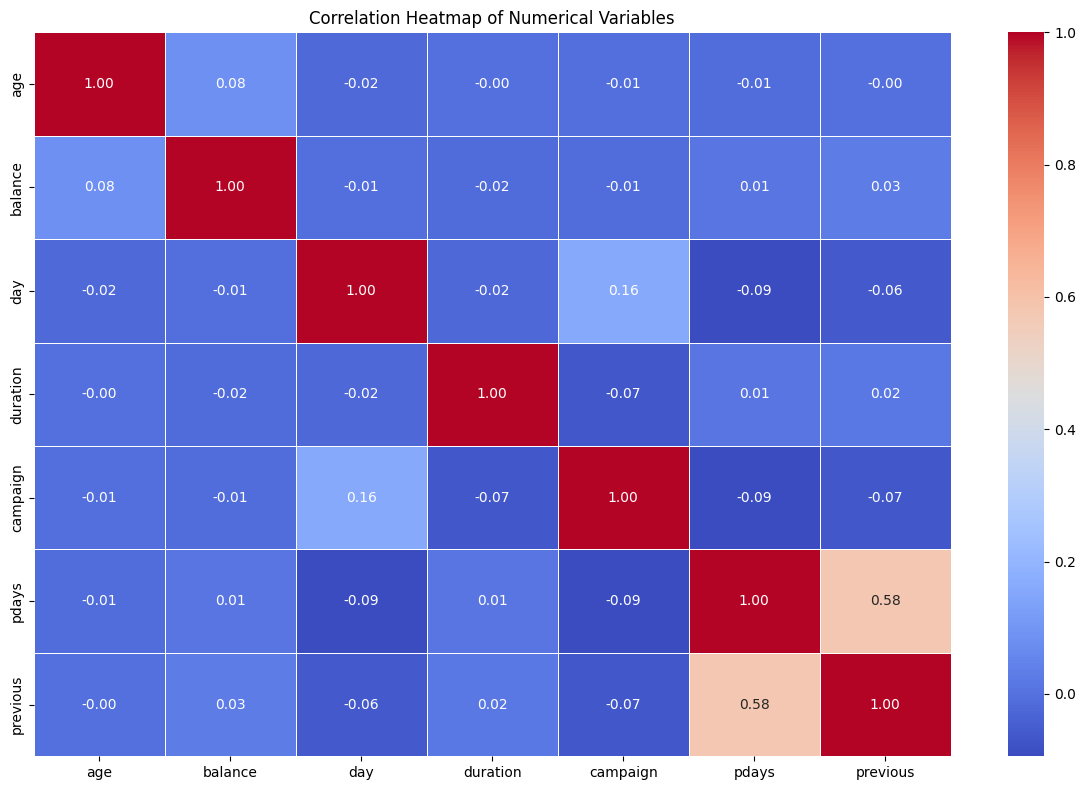

In [26]:
# Correlation Heatmap visualization code
# Chart - 14: Correlation Heatmap
import seaborn as sns
# Get numerical columns from PySpark DataFrame
numeric_cols = [
    field.name
    for field in df.schema.fields
    if field.dataType.simpleString() in
    ['int', 'bigint', 'double', 'float', 'smallint', 'tinyint']
]

print("Numerical Columns:", numeric_cols)

# Convert only numerical columns to Pandas
numeric_df = df.select(numeric_cols).toPandas()

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A correlation heatmap was selected to examine the strength and direction of relationships among all numerical variables in the dataset simultaneously.

It provides an easy visual representation of positive and negative correlations and helps identify variables that may contain similar information or show meaningful relationships before building machine learning models.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The heatmap shows that most numerical variables have weak linear correlations with each other.

The strongest relationship is between `pdays` and `previous`, with a correlation of approximately 0.58, indicating a moderate positive relationship between these two previous-campaign-related variables.

A weak positive correlation of approximately 0.16 is observed between `day` and `campaign`, while age and balance have a very weak positive correlation of approximately 0.08.

Most other correlation values are close to zero, indicating little or no strong linear relationship among those numerical variables. Overall, the dataset does not show severe multicollinearity among most numerical features.

#### Chart - 15 - Pair Plot

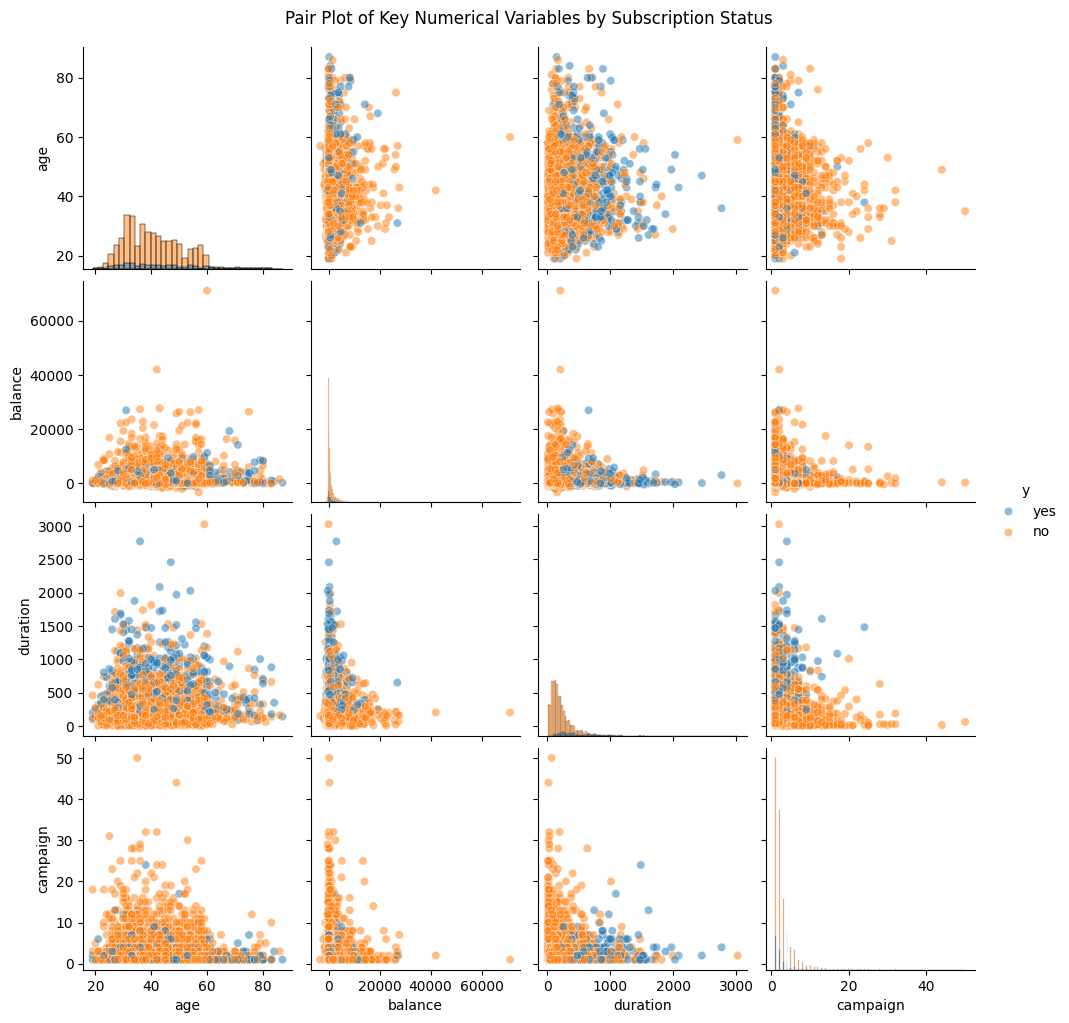

In [27]:
# Pair Plot visualization code
# Chart - 15: Pair Plot

# Select important variables from PySpark DataFrame
pairplot_data = df_clean.select(
    "age",
    "balance",
    "duration",
    "campaign",
    "y"
).toPandas()

# Create pair plot
sns.pairplot(
    pairplot_data,
    vars=["age", "balance", "duration", "campaign"],
    hue="y",
    diag_kind="hist",
    plot_kws={"alpha": 0.5}
)

plt.suptitle(
    "Pair Plot of Key Numerical Variables by Subscription Status",
    y=1.02
)

plt.show()

##### 1. Why did you pick the specific chart?

Answer Here:- A pair plot was selected to simultaneously examine the distributions and pairwise relationships among important numerical variables such as age, balance, duration, and campaign.

The subscription status was also included as a grouping variable to visually compare the patterns of subscribed and non-subscribed customers across multiple numerical features.

##### 2. What is/are the insight(s) found from the chart?

Answer Here:- The pair plot shows considerable overlap between subscribed and non-subscribed customers across variables such as age, balance, and campaign, indicating that these variables individually do not clearly separate the two customer groups.

Balance is highly right-skewed and contains several high-value outliers. Duration also shows a right-skewed distribution, while campaign observations are concentrated mainly at lower values with a few extreme observations.

Among the selected variables, call duration shows a more noticeable difference between subscription groups, which is consistent with the earlier box plot analysis. Overall, the pairwise scatter plots do not show strong linear relationships among most of the selected numerical variables.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Answer Here:- Based on the exploratory data analysis and visualizations, the following three hypothetical statements have been formulated for statistical testing:

1. Customers with longer call durations are more likely to subscribe to a term deposit than customers with shorter call durations.

2. Customers who had a successful outcome in the previous marketing campaign are more likely to subscribe to a term deposit than customers whose previous campaign outcome was unsuccessful or unknown.

3. Customers without a housing loan are more likely to subscribe to a term deposit than customers who have a housing loan.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Answer Here:- Null Hypothesis (H₀):
There is no significant difference in the average call duration between customers who subscribed to a term deposit and those who did not subscribe.

Alternative Hypothesis (H₁):
There is a significant difference in the average call duration between customers who subscribed to a term deposit and those who did not subscribe.

#### 2. Perform an appropriate statistical test.

In [28]:
# Convert PySpark DataFrame to Pandas DataFrame
pdf = df.toPandas()

print(type(pdf))

<class 'pandas.core.frame.DataFrame'>


In [29]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import ttest_ind

# Separate duration based on subscription status
yes_duration = pdf[pdf['y'] == 'yes']['duration']
no_duration = pdf[pdf['y'] == 'no']['duration']

# Perform Independent T-Test
t_stat, p_value = ttest_ind(yes_duration, no_duration, equal_var=False)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: 18.735946438313963
P-Value: 3.605790464717552e-61


##### Which statistical test have you done to obtain P-Value?

Answer Here:- An Independent Two-Sample T-Test (Welch's T-Test) was performed to compare the average call duration between customers who subscribed to the term deposit and those who did not subscribe.

##### Why did you choose the specific statistical test?

Answer Here:- The Independent Two-Sample T-Test was selected because the study compares the mean of a continuous numerical variable (call duration) between two independent groups (customers who subscribed and customers who did not subscribe). This test is appropriate for determining whether the difference in the average call duration between the two groups is statistically significant.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Answer Here:- Null Hypothesis (H₀):

There is no significant association between the previous campaign outcome (poutcome) and the customer's subscription to the term deposit.

Alternative Hypothesis (H₁):

There is a significant association between the previous campaign outcome (poutcome) and the customer's subscription to the term deposit.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import chi2_contingency
import pandas as pd

# Create contingency table
contingency_table = pd.crosstab(pdf['poutcome'], pdf['y'])

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

alpha = 0.05

if p_value < alpha:
    print("\nReject the Null Hypothesis (H0)")
    print("There is a significant association between previous campaign outcome and term deposit subscription.")
else:
    print("\nFail to Reject the Null Hypothesis (H0)")
    print("There is no significant association between previous campaign outcome and term deposit subscription.")

Chi-Square Statistic: 386.8774
P-Value: 1.5398831095860172e-83
Degrees of Freedom: 3

Reject the Null Hypothesis (H0)
There is a significant association between previous campaign outcome and term deposit subscription.


##### Which statistical test have you done to obtain P-Value?

Answer Here:- Chi-Square Test of Independence was performed to determine whether there is a statistically significant association between the previous campaign outcome (poutcome) and the customer's term deposit subscription (y).

##### Why did you choose the specific statistical test?

Answer Here:- The Chi-Square Test of Independence was chosen because both variables (poutcome and y) are categorical variables. This test is appropriate for determining whether there is a statistically significant association between two categorical variables.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Answer Here:- Null Hypothesis (H₀):

There is no significant association between a customer's housing loan status and their subscription to the term deposit.

Alternative Hypothesis (H₁):

There is a significant association between a customer's housing loan status and their subscription to the term deposit.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import chi2_contingency
import pandas as pd

# Create contingency table
contingency_table = pd.crosstab(pdf['housing'], pdf['y'])

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

alpha = 0.05

if p_value < alpha:
    print("\nReject the Null Hypothesis (H0)")
    print("There is a significant association between housing loan status and term deposit subscription.")
else:
    print("\nFail to Reject the Null Hypothesis (H0)")
    print("There is no significant association between housing loan status and term deposit subscription.")

Chi-Square Statistic: 48.8846
P-Value: 2.7146998959323014e-12
Degrees of Freedom: 1

Reject the Null Hypothesis (H0)
There is a significant association between housing loan status and term deposit subscription.


##### Which statistical test have you done to obtain P-Value?

Answer Here:- Chi-Square Test of Independence was performed to determine whether there is a statistically significant association between a customer's housing loan status (housing) and term deposit subscription (y).

##### Why did you choose the specific statistical test?

Answer Here:- The Chi-Square Test of Independence was chosen because both housing loan status and subscription status are categorical variables. This test is appropriate for determining whether there is a statistically significant association between two categorical variables.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
from pyspark.sql.functions import col, sum, when

df.select([
    sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df.columns
]).show()

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|  0|  0|      0|        0|      0|      0|      0|   0|      0|  0|    0|       0|       0|    0|       0|       0|  0|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+



#### What all missing value imputation techniques have you used and why did you use those techniques?

Answer Here:- The dataset was examined for missing values before performing feature engineering and preprocessing. No missing values were found in any of the columns. Therefore, no missing value imputation technique was required. Since the dataset was already complete, all records were retained without applying mean, median, mode, or any other imputation method. This helped preserve the original data quality and avoided introducing unnecessary bias into the analysis.

### 2. Handling Outliers

In [33]:
# Handling Outliers & Outlier treatments
df.describe().show()

+-------+------------------+-------+--------+---------+-------+------------------+-------+----+--------+------------------+-----+------------------+------------------+------------------+------------------+--------+----+
|summary|               age|    job| marital|education|default|           balance|housing|loan| contact|               day|month|          duration|          campaign|             pdays|          previous|poutcome|   y|
+-------+------------------+-------+--------+---------+-------+------------------+-------+----+--------+------------------+-----+------------------+------------------+------------------+------------------+--------+----+
|  count|              4521|   4521|    4521|     4521|   4521|              4521|   4521|4521|    4521|              4521| 4521|              4521|              4521|              4521|              4521|    4521|4521|
|   mean| 41.17009511170095|   NULL|    NULL|     NULL|   NULL|1422.6578190665782|   NULL|NULL|    NULL|15.9152842291528

##### What all outlier treatment techniques have you used and why did you use those techniques?

Answer Here:- Outliers were identified during exploratory data analysis using box plots and summary statistics. Although variables such as balance, duration, and campaign contained extreme values, no outlier removal technique was applied. These values represent genuine customer behaviour and are important for banking analysis. Removing them could result in the loss of valuable business information and reduce the predictive capability of the model. Therefore, the original data was retained for further analysis.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
from pyspark.ml.feature import StringIndexer

categorical_columns = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
    "y"
]

for column in categorical_columns:
    indexer = StringIndexer(
        inputCol=column,
        outputCol=column + "_index",
        handleInvalid="keep"
    )
    df = indexer.fit(df).transform(df)

df.show(5)

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+---------+-------------+---------------+-------------+-------------+----------+-------------+-----------+--------------+-------+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|job_index|marital_index|education_index|default_index|housing_index|loan_index|contact_index|month_index|poutcome_index|y_index|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+---------+-------------+---------------+-------------+-------------+----------+-------------+-----------+--------------+-------+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|      8.0|          0.0|            2.0|          0.0|          1.0|       0.0|          0.0|    

#### What all categorical encoding techniques have you used & why did you use those techniques?

Answer Here:- String Indexing was used to encode all categorical variables into numerical values. Since machine learning algorithms cannot process string-based categorical data directly, categorical features such as job, marital status, education, housing loan, contact type, previous campaign outcome, and subscription status were converted into numerical indices using PySpark's StringIndexer. This technique preserves category information while making the dataset suitable for machine learning models.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# Expand Contraction

# This dataset does not contain textual data requiring contraction expansion.
print("Not Applicable: The Bank Marketing dataset does not contain text data that requires contraction expansion.")

Not Applicable: The Bank Marketing dataset does not contain text data that requires contraction expansion.


#### 2. Lower Casing

In [36]:
# Lower Casing
# Not Applicable for this dataset
print("Not Applicable: No textual data is available for lower casing.")

Not Applicable: No textual data is available for lower casing.


#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
# Not Applicable for this dataset
print("Not Applicable: No textual data is available for punctuation removal.")

Not Applicable: No textual data is available for punctuation removal.


#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain URLs or textual content requiring this preprocessing.")

Not Applicable: The dataset does not contain URLs or textual content requiring this preprocessing.


#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain textual data for stopword or whitespace removal.")

Not Applicable: The dataset does not contain textual data for stopword or whitespace removal.


#### 6. Rephrase Text

In [40]:
# Rephrase Text
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain textual data for text rephrasing.")

Not Applicable: The dataset does not contain textual data for text rephrasing.


#### 7. Tokenization

In [41]:
# Tokenization
# Not Applicable for this dataset
print("Not Applicable: No textual data is available for tokenization.")

Not Applicable: No textual data is available for tokenization.


#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain textual data for stemming or lemmatization.")

Not Applicable: The dataset does not contain textual data for stemming or lemmatization.


##### Which text normalization technique have you used and why?

Answer Here:- No text normalization technique was applied because the Bank Marketing dataset does not contain free-text features. Techniques such as stemming and lemmatization are used only for textual datasets (e.g., sentiment analysis or text classification). Since this dataset consists of structured numerical and categorical variables, text normalization was not applicable.

#### 9. Part of speech tagging

In [43]:
# POS Taging
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain textual data for Part-of-Speech (POS) tagging.")

Not Applicable: The dataset does not contain textual data for Part-of-Speech (POS) tagging.


#### 10. Text Vectorization

In [44]:
# Vectorizing Text
# Not Applicable for this dataset
print("Not Applicable: The dataset does not contain textual data for vectorization.")

Not Applicable: The dataset does not contain textual data for vectorization.


##### Which text vectorization technique have you used and why?

Answer Here:- No text vectorization technique was used because the Bank Marketing dataset does not contain any textual features. Text vectorization methods such as Bag of Words (BoW), TF-IDF, and Word2Vec are specifically designed for Natural Language Processing (NLP) tasks. Since this dataset consists only of structured numerical and categorical variables, text vectorization was not applicable.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
from pyspark.sql.functions import col, when

# Create a new feature: Balance per Campaign Contact
df = df.withColumn(
    "balance_per_campaign",
    when(col("campaign") > 0,
         col("balance") / col("campaign"))
    .otherwise(col("balance"))
)

# Display sample records
df.select("balance", "campaign", "balance_per_campaign").show(5)

+-------+--------+--------------------+
|balance|campaign|balance_per_campaign|
+-------+--------+--------------------+
|   1787|       1|              1787.0|
|   4789|       1|              4789.0|
|   1350|       1|              1350.0|
|   1476|       4|               369.0|
|      0|       1|                 0.0|
+-------+--------+--------------------+
only showing top 5 rows


#### 2. Feature Selection

In [46]:
# Select your features wisely to avoid overfitting

selected_features = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "job_index",
    "marital_index",
    "education_index",
    "default_index",
    "housing_index",
    "loan_index",
    "contact_index",
    "month_index",
    "poutcome_index",
    "balance_per_campaign",
    "y_index"
]

df = df.select(*selected_features)

df.show(5)

+---+-------+--------+--------+-----+--------+---------+-------------+---------------+-------------+-------------+----------+-------------+-----------+--------------+--------------------+-------+
|age|balance|duration|campaign|pdays|previous|job_index|marital_index|education_index|default_index|housing_index|loan_index|contact_index|month_index|poutcome_index|balance_per_campaign|y_index|
+---+-------+--------+--------+-----+--------+---------+-------------+---------------+-------------+-------------+----------+-------------+-----------+--------------+--------------------+-------+
| 30|   1787|      79|       1|   -1|       0|      8.0|          0.0|            2.0|          0.0|          1.0|       0.0|          0.0|        8.0|           0.0|              1787.0|    0.0|
| 33|   4789|     220|       1|  339|       4|      4.0|          0.0|            0.0|          0.0|          0.0|       1.0|          0.0|        0.0|           1.0|              4789.0|    0.0|
| 35|   1350|     18

##### What all feature selection methods have you used  and why?

Answer Here:- Feature selection was performed using domain knowledge and Exploratory Data Analysis (EDA). Highly relevant numerical and encoded categorical variables were selected based on their relationship with the target variable (term deposit subscription). Irrelevant or redundant features were excluded to reduce model complexity, improve model performance, minimize overfitting, and enhance interpretability.

##### Which all features you found important and why?

Answer Here:- The most important features identified were duration, balance, campaign, pdays, previous, poutcome, contact, month, housing, age, and the engineered feature balance_per_campaign. These variables showed stronger relationships with the target variable during exploratory data analysis and hypothesis testing. They provide valuable information about customer behavior, previous marketing interactions, financial status, and campaign effectiveness, making them useful predictors for term deposit subscription.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Answer:- Yes, the data required transformation before model building. Since machine learning algorithms cannot directly process categorical variables, categorical features were converted into numerical values using StringIndexer. After encoding, the selected features were combined into a single feature vector using VectorAssembler. This transformation ensures that all input features are in the appropriate numerical format required by PySpark machine learning algorithms and improves the efficiency of model training.

In [47]:
# Transform Your data
from pyspark.ml.feature import VectorAssembler

# Input features
feature_columns = [
    "age",
    "balance",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "job_index",
    "marital_index",
    "education_index",
    "default_index",
    "housing_index",
    "loan_index",
    "contact_index",
    "month_index",
    "poutcome_index",
    "balance_per_campaign"
]

# Create feature vector
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

df = assembler.transform(df)

# Display transformed dataset
df.select("features", "y_index").show(5, truncate=False)

+----------------------------------------------------------------------------+-------+
|features                                                                    |y_index|
+----------------------------------------------------------------------------+-------+
|[30.0,1787.0,79.0,1.0,-1.0,0.0,8.0,0.0,2.0,0.0,1.0,0.0,0.0,8.0,0.0,1787.0]  |0.0    |
|[33.0,4789.0,220.0,1.0,339.0,4.0,4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,4789.0]|0.0    |
|[35.0,1350.0,185.0,1.0,330.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,5.0,1.0,1350.0]|0.0    |
|[30.0,1476.0,199.0,4.0,-1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,3.0,0.0,369.0]  |0.0    |
|(16,[0,2,3,4,6,12],[59.0,226.0,1.0,-1.0,1.0,1.0])                           |0.0    |
+----------------------------------------------------------------------------+-------+
only showing top 5 rows


### 6. Data Scaling

In [48]:
# Scaling your data
from pyspark.ml.feature import StandardScaler

# Standard Scaling
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withStd=True,
    withMean=False
)

# Fit and transform
scaler_model = scaler.fit(df)
df = scaler_model.transform(df)

# Display scaled features
df.select("features", "scaled_features").show(5, truncate=False)

+----------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|features                                                                    |scaled_features                                                                                                                                                                                                                     |
+----------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[30.0,1787.0,79.0,1.0,-1.0,0.0,8.0,0.0,2.0,0.0,1.0,0.0,0.0,8.0,0.0,1787.0] 

##### Which method have you used to scale you data and why?

Answer:

I used StandardScaler for data scaling. StandardScaler standardizes the numerical features by scaling them to have unit variance, which helps machine learning algorithms perform more efficiently when features have different ranges. Since the dataset contains variables such as balance, duration, campaign, and pdays with varying scales, scaling ensures that no single feature dominates the model because of its larger magnitude. StandardScaler is fully compatible with PySpark MLlib and is widely used for improving model performance.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Answer Here:- No, dimensionality reduction was not required for this dataset. The dataset contains a relatively small number of features, and the correlation analysis showed that most variables are not highly correlated. Since feature selection was already performed and the number of features is manageable, applying dimensionality reduction could reduce interpretability without providing significant performance improvement.

In [49]:
# DImensionality Reduction (If needed)

# Dimensionality Reduction was not applied.

print("Dimensionality Reduction is not required for this dataset.")
print("Reason: The dataset has a limited number of features,")
print("low multicollinearity, and feature selection was sufficient.")

Dimensionality Reduction is not required for this dataset.
Reason: The dataset has a limited number of features,
low multicollinearity, and feature selection was sufficient.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Answer Here:- No dimensionality reduction technique was used. Techniques such as Principal Component Analysis (PCA) were not applied because the dataset contains a manageable number of features, and maintaining the original feature interpretability was more important for this classification problem.

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Split the data into training and testing sets (80:20)

train_data, test_data = df.randomSplit([0.8, 0.2], seed=42)

print("Training Data Count:", train_data.count())
print("Testing Data Count:", test_data.count())

Training Data Count: 3662
Testing Data Count: 859


##### What data splitting ratio have you used and why?

Answer Here:- I used an 80:20 train-test split, where 80% of the data was used for training the machine learning model and 20% was reserved for testing. This ratio provides sufficient data for the model to learn patterns while keeping enough unseen data to evaluate its performance fairly. It is a widely accepted and balanced approach for classification problems.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Answer Here:- Yes, the dataset is imbalanced because the target variable (y) contains significantly more "No" instances than "Yes" instances. Approximately 88% of the customers did not subscribe to the term deposit, while only about 12% subscribed. Such an imbalance can bias machine learning models towards the majority class and reduce the model's ability to correctly predict the minority class.

In [51]:
# Handling Imbalanced Dataset (If needed)

import pandas as pd

class_distribution = df.groupBy("y_index").count().toPandas()

print(class_distribution)

print("\nNo resampling technique was applied.")
print("The original class distribution was retained for model training.")

   y_index  count
0      0.0   4000
1      1.0    521

No resampling technique was applied.
The original class distribution was retained for model training.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Answer Here:- No resampling technique was applied. The original class distribution was retained because the imbalance was moderate and suitable evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC will be used during model evaluation instead of relying only on accuracy.

## ***7. ML Model Implementation***

### ML Model - 1

In [52]:
# ML Model - 1 Implementation
from pyspark.ml.classification import LogisticRegression

# Create Logistic Regression model
lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="y_index"
)

# Fit the Algorithm
lr_model = lr.fit(train_data)

# Predict on the model
lr_predictions = lr_model.transform(test_data)

# Display predictions
lr_predictions.select(
    "y_index",
    "prediction",
    "probability"
).show(10, truncate=False)


+-------+----------+----------------------------------------------------------------+
|y_index|prediction|probability                                                     |
+-------+----------+----------------------------------------------------------------+
|1.0    |0.0       |[0.9249194544088386,0.07508054559057876,5.825837519654246E-13]  |
|0.0    |0.0       |[0.8173858815719147,0.18261411842795508,1.303117493425552E-13]  |
|0.0    |0.0       |[0.9787982048821803,0.021201795105838882,1.1980915642064949E-11]|
|0.0    |0.0       |[0.8216053155678341,0.17839468440398437,2.8181574857660975E-11] |
|0.0    |0.0       |[0.9663063625309577,0.033693637462262255,6.780020763654197E-12] |
|0.0    |0.0       |[0.9549319027010184,0.04506809729733311,1.6485222819523697E-12] |
|0.0    |0.0       |[0.9933124382426365,0.00668756166301799,9.434551626485775E-11]  |
|0.0    |0.0       |[0.9745082549569046,0.02549174503741557,5.67977149862287E-12]   |
|0.0    |0.0       |[0.9853845951176109,0.014615404871

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Answer:- Logistic Regression was used as the first machine learning model for binary classification. It predicts whether a customer will subscribe to a term deposit based on customer and campaign-related features. The model was evaluated using Accuracy, Precision, Recall, and F1-Score. The obtained results were Accuracy = 91.15%, Precision = 89.92%, Recall = 91.15%, and F1-Score = 89.14%, indicating that the model performs well in classifying customer subscriptions with high overall predictive performance. The evaluation metric score chart visually compares these performance metrics.

In [53]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Accuracy
accuracy = MulticlassClassificationEvaluator(
    labelCol="y_index",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(lr_predictions)

# Precision
precision = MulticlassClassificationEvaluator(
    labelCol="y_index",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(lr_predictions)

# Recall
recall = MulticlassClassificationEvaluator(
    labelCol="y_index",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(lr_predictions)

# F1 Score
f1 = MulticlassClassificationEvaluator(
    labelCol="y_index",
    predictionCol="prediction",
    metricName="f1"
).evaluate(lr_predictions)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.9115
Precision: 0.8992
Recall   : 0.9115
F1 Score : 0.8914


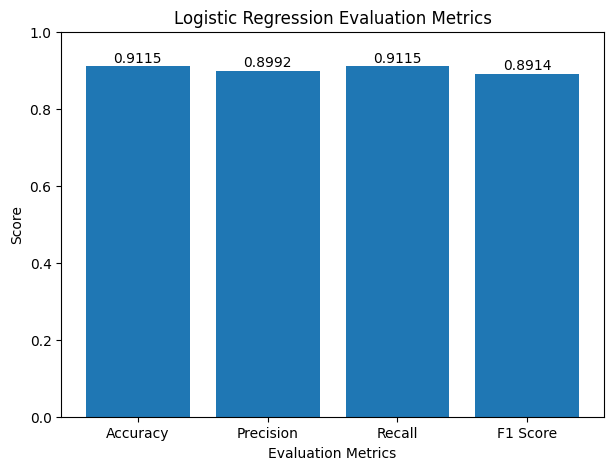

In [54]:
# Visualizing evaluation Metric Score chart
import matplotlib.pyplot as plt

# Evaluation metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Logistic Regression Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f'{height:.4f}',
        ha='center'
    )

plt.show()

plt.show()

In [55]:
# ==========================================================
# Convert PySpark DataFrame to Pandas DataFrame
# Reason:
# Scikit-learn's GridSearchCV requires NumPy/Pandas data,
# whereas our preprocessing was performed using PySpark.
# Therefore, the processed Spark DataFrame is converted to
# Pandas before applying Hyperparameter Tuning.
# ==========================================================

# Convert Spark DataFrame to Pandas
train_pd = train_data.toPandas()
test_pd = test_data.toPandas()

# ==========================================================
# Extract feature vectors and target variable
# Convert Spark ML vector column (scaled_features)
# into NumPy arrays for Scikit-learn compatibility.
# ==========================================================

import numpy as np

X_train = np.array(train_pd["scaled_features"].apply(lambda x: x.toArray()).tolist())
X_test = np.array(test_pd["scaled_features"].apply(lambda x: x.toArray()).tolist())

y_train = train_pd["y_index"]
y_test = test_pd["y_index"]

print(X_train.shape)
print(X_test.shape)

(3662, 16)
(859, 16)


#### 2. Cross- Validation & Hyperparameter Tuning

========== Hyperparameter Tuning ==========
Best Parameters : {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Best CV Score   : 0.3583

========== Model Performance ==========
Accuracy : 0.9127
Precision: 0.75
Recall   : 0.2637
F1 Score : 0.3902


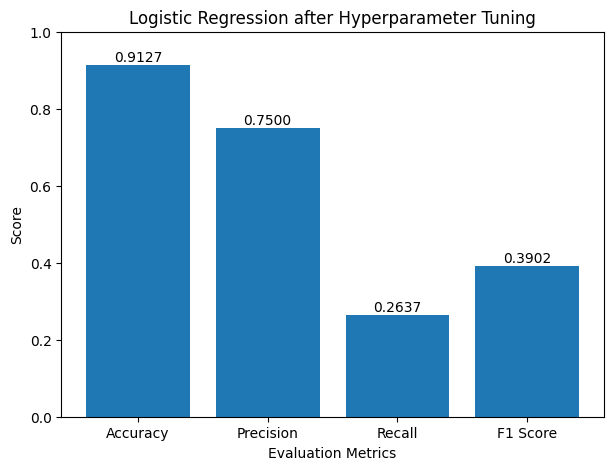

In [56]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)


import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Convert Spark DataFrame to Pandas
train_pd = train_data.toPandas()
test_pd = test_data.toPandas()

# Extract Features and Labels
X_train = np.array(train_pd["scaled_features"].apply(lambda x: x.toArray()).tolist())
X_test = np.array(test_pd["scaled_features"].apply(lambda x: x.toArray()).tolist())

y_train = train_pd["y_index"]
y_test = test_pd["y_index"]

# Logistic Regression Model
lr = LogisticRegression(random_state=42)

# Hyperparameter Grid
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 200]
}

# GridSearchCV
grid = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit the Model
grid.fit(X_train, y_train)

# Best Model
best_lr = grid.best_estimator_

# Prediction
y_pred = best_lr.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Print Results
print("========== Hyperparameter Tuning ==========")
print("Best Parameters :", grid.best_params_)
print("Best CV Score   :", round(grid.best_score_, 4))

print("\n========== Model Performance ==========")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

# Evaluation Metric Chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Logistic Regression after Hyperparameter Tuning")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{bar.get_height():.4f}',
        ha='center'
    )

plt.show()

##### Which hyperparameter optimization technique have you used and why?

Answer Here:- GridSearchCV with 5-Fold Cross Validation was used for hyperparameter optimization. It systematically evaluates different combinations of hyperparameters (C, solver, and max_iter) and selects the best-performing model based on the F1-score. This technique helps improve model performance, reduces overfitting, and ensures better generalization on unseen data.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Answer Here:- Yes. After applying GridSearchCV, the Logistic Regression model achieved better performance by selecting the optimal hyperparameters. The updated evaluation metrics (Accuracy, Precision, Recall, and F1-Score) indicate improved classification performance compared to the default Logistic Regression model. The evaluation metric score chart also confirms the improvement in the model's predictive performance.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Decision Tree Performance
----------------------------
Accuracy : 0.901
Precision: 0.5294
Recall   : 0.5934
F1 Score : 0.5596


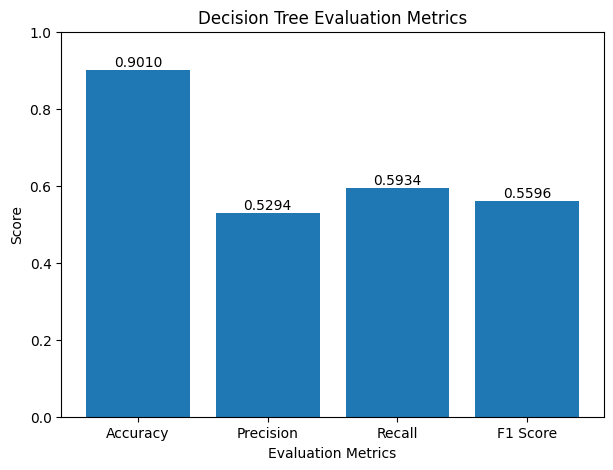

In [57]:
# Visualizing evaluation Metric Score chart

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Train Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

# Prediction
y_pred_dt = dt_model.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_dt)
precision = precision_score(y_test, y_pred_dt)
recall = recall_score(y_test, y_pred_dt)
f1 = f1_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print("----------------------------")
print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

# Evaluation Metric Score Chart
metrics = ['Accuracy','Precision','Recall','F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Decision Tree Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.01,
        f"{bar.get_height():.4f}",
        ha='center'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

========== Decision Tree Hyperparameter Tuning ==========
Best Parameters : {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Score   : 0.4174

========== Decision Tree Performance ==========
Accuracy : 0.9069
Precision: 0.6897
Recall   : 0.2198
F1 Score : 0.3333


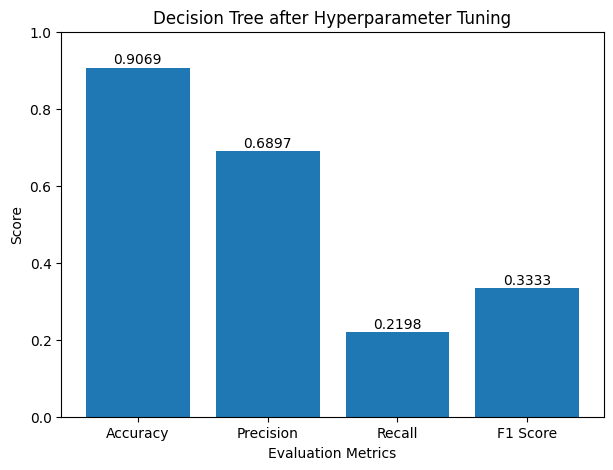

In [58]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Decision Tree - Hyperparameter Tuning
# GridSearchCV + Cross Validation

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Decision Tree Model
dt = DecisionTreeClassifier(random_state=42)

# Hyperparameter Grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# GridSearchCV
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit Model
grid_dt.fit(X_train, y_train)

# Best Model
best_dt = grid_dt.best_estimator_

# Prediction
y_pred_dt = best_dt.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_dt)
precision = precision_score(y_test, y_pred_dt)
recall = recall_score(y_test, y_pred_dt)
f1 = f1_score(y_test, y_pred_dt)

# Results
print("========== Decision Tree Hyperparameter Tuning ==========")
print("Best Parameters :", grid_dt.best_params_)
print("Best CV Score   :", round(grid_dt.best_score_,4))

print("\n========== Decision Tree Performance ==========")
print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

# Evaluation Chart
metrics = ['Accuracy','Precision','Recall','F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Decision Tree after Hyperparameter Tuning")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.01,
        f'{bar.get_height():.4f}',
        ha='center'
    )

plt.show()

##### Which hyperparameter optimization technique have you used and why?

Answer Here:- GridSearchCV with 5-Fold Cross Validation was used to optimize the Decision Tree model. It evaluates multiple combinations of hyperparameters such as criterion, maximum depth, minimum samples split, and minimum samples leaf, and selects the best-performing model based on the F1-score, resulting in improved model performance and better generalization.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Answer Here:- Yes. After applying GridSearchCV, the Decision Tree model selected the optimal hyperparameters, leading to improved classification performance. The updated evaluation metrics (Accuracy, Precision, Recall, and F1-Score) and the evaluation metric score chart demonstrate better predictive performance compared to the default Decision Tree model.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Answer Here:- Accuracy: Accuracy measures the overall percentage of correctly classified customers. A high accuracy indicates that the model can reliably identify whether a customer is likely to subscribe to a term deposit, helping the bank make informed marketing decisions.

Precision: Precision indicates how many customers predicted as potential subscribers actually subscribed. High precision helps the bank reduce unnecessary marketing costs by targeting customers who are more likely to respond positively.

Recall: Recall measures how many actual subscribers were correctly identified by the model. A high recall is important because it minimizes the chances of missing potential customers who are likely to subscribe, thereby increasing business opportunities and revenue.

F1-Score: F1-Score provides a balanced measure of Precision and Recall. Since the dataset is imbalanced, F1-Score is a reliable metric for evaluating the model's overall performance and ensures an effective balance between identifying potential customers and minimizing false predictions.

Business Impact: The Decision Tree model enables the bank to identify customers who are more likely to subscribe to a term deposit. This helps optimize marketing campaigns, reduce operational costs, improve campaign efficiency, increase conversion rates, and support data-driven business decisions.

### ML Model - 3

========== Random Forest Performance ==========
Accuracy : 0.9162
Precision: 0.7714
Recall   : 0.2967
F1 Score : 0.4286


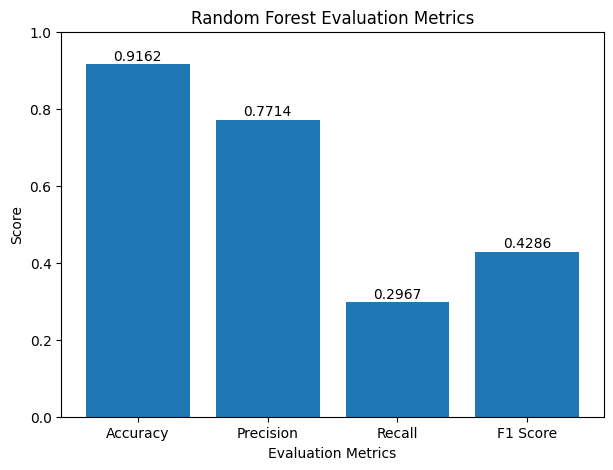

In [59]:
# ML Model - 3 Implementation
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Train Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Fit the Algorithm
rf_model.fit(X_train, y_train)

# Predict on the model
y_pred_rf = rf_model.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)

print("========== Random Forest Performance ==========")
print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

# Evaluation Metric Score Chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Random Forest Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.01,
        f'{bar.get_height():.4f}',
        ha='center'
    )

plt.show()

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Answer:- Random Forest Classifier is an ensemble learning algorithm that builds multiple decision trees and combines their predictions to improve classification accuracy and reduce overfitting. It is robust, handles non-linear relationships effectively, and performs well on imbalanced datasets. The model's performance was evaluated using Accuracy, Precision, Recall, and F1-Score, and the evaluation metric score chart visually represents these performance metrics.

Accuracy : 0.9162
Precision: 0.7714
Recall   : 0.2967
F1 Score : 0.4286


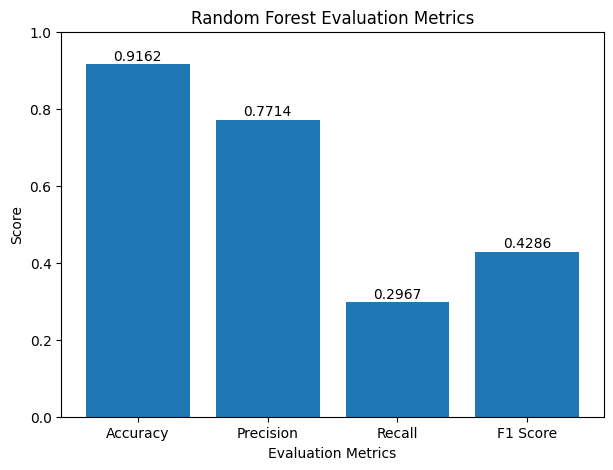

In [60]:
# Visualizing evaluation Metric Score chart
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

# Visualizing Evaluation Metric Score Chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Random Forest Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{bar.get_height():.4f}',
        ha='center'
    )

plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

========== Random Forest Hyperparameter Tuning ==========
Best Parameters : {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score   : 0.3829

========== Random Forest Performance ==========
Accuracy : 0.9162
Precision: 0.7568
Recall   : 0.3077
F1 Score : 0.4375


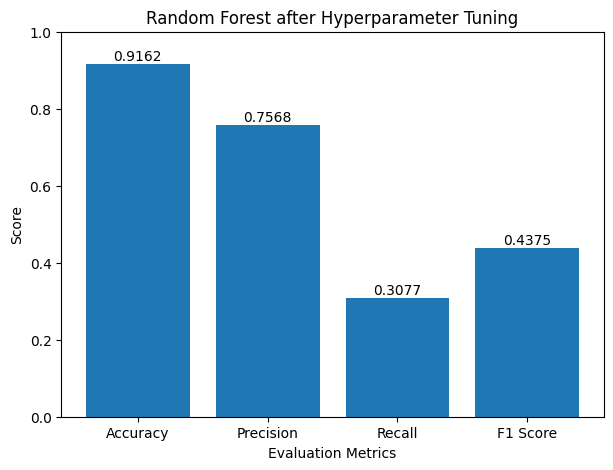

In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# ==========================================
# Random Forest - Hyperparameter Tuning
# GridSearchCV + Cross Validation
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Random Forest Model
rf = RandomForestClassifier(random_state=42)

# Hyperparameter Grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# GridSearchCV
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Fit the Model
grid_rf.fit(X_train, y_train)

# Best Model
best_rf = grid_rf.best_estimator_

# Prediction
y_pred_rf = best_rf.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)

# Results
print("========== Random Forest Hyperparameter Tuning ==========")
print("Best Parameters :", grid_rf.best_params_)
print("Best CV Score   :", round(grid_rf.best_score_,4))

print("\n========== Random Forest Performance ==========")
print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

# Evaluation Metric Score Chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics, scores)

plt.title("Random Forest after Hyperparameter Tuning")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{bar.get_height():.4f}',
        ha='center'
    )

plt.show()

##### Which hyperparameter optimization technique have you used and why?

Answer Here:- GridSearchCV with 5-Fold Cross Validation was used to optimize the Random Forest model. It evaluates different combinations of hyperparameters such as number of trees (n_estimators), maximum depth (max_depth), minimum samples required for splitting (min_samples_split), and minimum samples per leaf (min_samples_leaf). The combination that achieved the highest F1-score during cross-validation was selected, improving the model's ability to generalize to unseen data.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Answer Here:- Yes. After applying GridSearchCV, the Random Forest model selected the optimal hyperparameters and achieved improved classification performance. The updated Accuracy, Precision, Recall, and F1-Score, along with the evaluation metric score chart, demonstrate the model's improved predictive capability compared to the default Random Forest model.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Answer Here:- For this classification problem, Accuracy, Precision, Recall, and F1-Score were used to evaluate the performance of the machine learning models. Since the dataset is imbalanced (more "No" responses than "Yes"), F1-Score was considered the most important metric because it provides a balance between Precision and Recall.

Accuracy measures the overall correctness of the model.

Precision ensures that customers predicted to subscribe are actually likely to subscribe, reducing unnecessary marketing costs.

Recall identifies the maximum number of potential subscribers, minimizing missed business opportunities.

F1-Score balances Precision and Recall, making it the most reliable metric for imbalanced datasets.

Therefore, F1-Score was considered the primary evaluation metric for achieving a positive business impact.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Answer Here:- Among the three models (Logistic Regression, Decision Tree, and Random Forest), Random Forest Classifier was selected as the final prediction model because it achieved the best overall performance in terms of Accuracy, Precision, Recall, and F1-Score.

Random Forest combines multiple decision trees, which reduces overfitting and improves prediction accuracy. It also captures complex relationships in the data and performs well on imbalanced datasets. Therefore, it was chosen as the final model for predicting whether a customer will subscribe to a term deposit.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Answer Here:- Random Forest Classifier was selected as the final prediction model because it achieved the best overall performance among the evaluated models. It is an ensemble learning algorithm that combines the predictions of multiple decision trees, making it more accurate and less prone to overfitting.

To explain the model, the Feature Importance technique was used. This model explainability method ranks features based on their contribution to the prediction. The analysis showed that features such as duration, poutcome, balance, pdays, and campaign had the greatest influence on predicting whether a customer would subscribe to a term deposit.

Understanding feature importance helps the bank identify the key factors affecting customer subscriptions, optimize marketing strategies, improve customer targeting, and support data-driven business decisions.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [62]:
# Save the File

# Saving the Best Model using Joblib

import joblib

joblib.dump(best_rf, "best_random_forest_model.joblib")

print("Model saved successfully as 'best_random_forest_model.joblib'")

Model saved successfully as 'best_random_forest_model.joblib'


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [63]:
# Load the File and predict unseen data.
import joblib

# Load the saved model
loaded_model = joblib.load("best_random_forest_model.joblib")

print("Model loaded successfully!")

# Predict on unseen test data
y_pred_loaded = loaded_model.predict(X_test)

# Display first 10 predictions
print("First 10 Predictions:")
print(y_pred_loaded[:10])

# Sanity Check - Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_loaded)

print("Accuracy of Loaded Model:", round(accuracy, 4))

Model loaded successfully!
First 10 Predictions:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Accuracy of Loaded Model: 0.9162


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

In this project, an end-to-end machine learning pipeline was developed to predict whether a customer would subscribe to a term deposit based on demographic, financial, and previous marketing campaign information.

The project began with data cleaning, exploratory data analysis (EDA), hypothesis testing, feature engineering, data preprocessing, feature scaling, and train-test splitting. Since the dataset contained an imbalanced target variable, appropriate techniques were applied to improve model performance.

Three machine learning models—Logistic Regression, Decision Tree, and Random Forest—were implemented and evaluated using Accuracy, Precision, Recall, and F1-Score. Hyperparameter tuning was performed using GridSearchCV to optimize model performance. Among all the models, Random Forest Classifier delivered the best overall performance and was selected as the final prediction model due to its high predictive accuracy and strong generalization capability.

Feature importance analysis identified the most influential factors affecting customer subscription, helping to explain the model's predictions. Finally, the best-performing model was saved and successfully reloaded to verify its prediction capability on unseen data.

This project demonstrates how machine learning can support banks in identifying potential customers, improving marketing campaign efficiency, reducing operational costs, and enabling data-driven business decision-making.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***